# Introducción a las Redes Neuronales.

En esta libreta mostraremos el funcionamento de una red neuronal. Esto sin el uso de librerias estándar.

## Paso 1: Definir el problema

Por el Teorema de Cybenko sabemos que para la función $f(x)=\sqrt{x}$. Dado $\epsilon>0$, existe una red neuronal $\mathfrak{m}(\cdot,\Theta)$ tal que

$$
    |\mathfrak{m}(x,\Theta)-\sqrt{x}|<\epsilon
$$

Entonces construiremos una red neuronal que estime la función raiz cuadrada. 

In [186]:
import numpy as np


def sigmoide(x):
    return (1 + np.exp(-x)) ** (-1)


def model(x, pars):
    c = pars[0]
    w = pars[1]
    b = pars[2]
    v = w * x + b
    y = c * sigmoide(v)
    return y


def partial_nn(pars, var, h = 10 ** (-5), f=model):
    assert var in (0,1,2)
    vh = np.zeros(3)
    vh[var] += h
    vh += pars
    partial = h ** (-1) * (f(vh) - f(pars))
    return partial





In [275]:
N = 10
Np = 20
train_x = np.linspace(-N, N, Np)
train_y = np.int16(train_x > 0)

def sce_nn(pars, x=train_x, y=train_y):
    error = (y - model(x, pars)) ** 2
    return Np ** (-1) * error.sum()


def gradient(pars):
    grad = [partial_nn(pars, v, f=sce_nn) for v in range(3)]
    return np.array(grad)


gamma = 0.1
pars = [1,1,1]
pars = np.array(pars)

eps = 10 ** (-2)
x_0 = pars

for epocs in range(1_000):
    g_0 = gradient(x_0)
    x_n = x_0 - gamma * g_0
    x_0 = x_n
    if epocs % 100 == 0:
        print(epocs, sce_nn(x_0))
print("Parametro final",x_0, "Error Final", sce_nn(x_0))


0 0.028670828270738902
100 0.020028854108224647
200 0.015872426849629348
300 0.013286324207127047
400 0.011509920655824311
500 0.010214160137070011
600 0.009227855333127349
700 0.008451662307861893
800 0.007823753104207217
900 0.007303755771798304
Parametro final [1.01185264 2.03505718 0.20868595] Error Final 0.006868420780283106


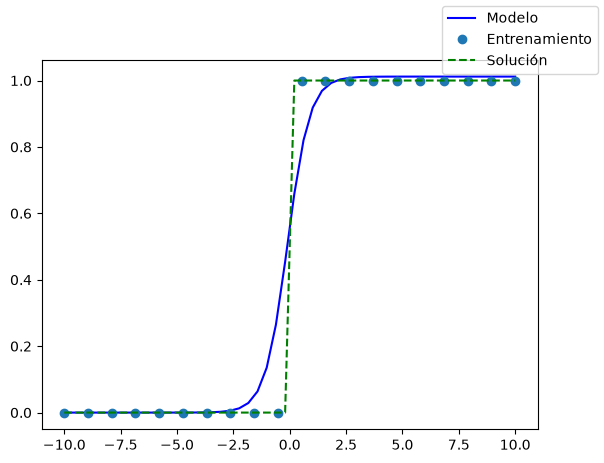

In [276]:
import matplotlib.pyplot as plt


x_test = np.linspace(-N, N, 50)
y_test = model(x_test, x_0)
y_sol = np.int16(x_test > 0)

fig, ax = plt.subplots()
ax.plot(x_test, y_test, color="blue", label="Modelo")
ax.plot(train_x, train_y, "o", label="Entrenamiento")
ax.plot(x_test,y_sol, "g--", label="Solución")
fig.legend()